Name: Fateh Noor <br>
CMS-ID: 023-24-0110<br>
Github: 

In [1]:
import pandas as pd 
import numpy as np 
df=pd.read_csv("healthcare-dataset-stroke-data_1 (1).csv")
shape=df.shape
print(f"Dataset Shape: {shape}")
missingcolumns=df.isnull().sum()[df.isnull().sum()>0]
print(f"Columns with Missing values: {missingcolumns}")
gender_count=df["gender"].value_counts()
print(f"Value counts of gender: {gender_count}")
print(f"No of Patients with stroke: {len(df[df["stroke"]==1])}")
print(f"No of Patients with no stroke: {len(df[df["stroke"]==0])}")


Dataset Shape: (5110, 12)
Columns with Missing values: bmi    201
dtype: int64
Value counts of gender: gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64
No of Patients with stroke: 249
No of Patients with no stroke: 4861


In [2]:
df=df.drop(columns=["id"])
df=df[df["gender"]!="Other"]
y=df["stroke"]
x=df.drop(columns=["stroke"])
x=pd.get_dummies(x,drop_first=True)

In [3]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)
num_col=x_train.select_dtypes(include="number").columns
median=x_train[num_col].median()
x_train[num_col]=x_train[num_col].fillna(median)
x_test[num_col]=x_test[num_col].fillna(median)
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train_scale=scaler.fit_transform(x_train)
x_test_scale=scaler.transform(x_test)

In [4]:
stroke_train=len(y_train[y_train==1])
stroke_test=len(y_test[y_test==1])
print(f"No of stroke cases in training set: {stroke_train}")
print(f"No of stroke cases in testing set: {stroke_test}")

No of stroke cases in training set: 199
No of stroke cases in testing set: 50


(a)	In 2-3 lines: how imbalanced is the data? Why did we use stratify=y, and what could go wrong with only a few stroke cases in the test set?<br>
The dataset is highly imbalanced because stroke cases are much fewer than non-stroke cases. Our training set contains 199 stroke patients, while the testing set contains 50 stroke patients. We used stratify=y to maintain the same class distribution in both sets. Without stratification, the test set might contain very few stroke cases, making model evaluation and performance metrics unreliable.

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
dummy=DummyClassifier(strategy="most_frequent")
dummy.fit(x_train,y_train)
dummy_pred=dummy.predict(x_test)
dummy_acc=accuracy_score(y_test,dummy_pred)
print(f"Dummy Accuracy: {dummy_acc:.2f}")

Dummy Accuracy: 0.95


Logistic regression accuracy: 0.95
Logistic regression precision: 0.02
Logistic regression recall: 1.00
Logistic regression F1 score: 0.04
Logistic regression ROC AUC score: 0.84
Logistic regression Average Precision Score: 0.27


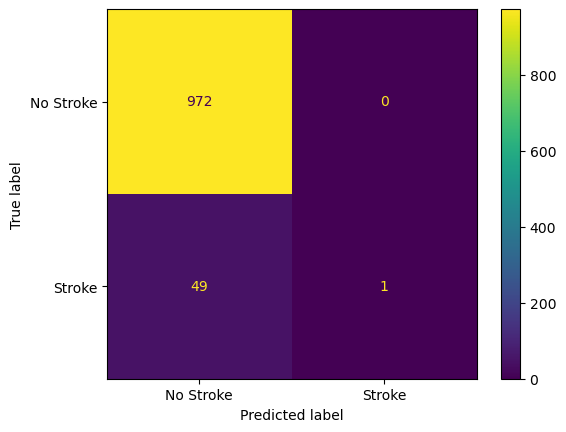

In [6]:
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression()
lr.fit(x_train_scale,y_train)
lr_pred=lr.predict(x_test_scale)
from sklearn.metrics import (precision_score,recall_score,f1_score,roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay)
import matplotlib.pyplot as plt
lr_acc=accuracy_score(lr_pred,y_test)
lr_prec=precision_score(lr_pred,y_test)
lr_rec=recall_score(lr_pred,y_test)
lr_f1=f1_score(lr_pred,y_test)
y_prob=lr.predict_proba(x_test_scale)[:,1]
lr_roc=roc_auc_score(y_test,y_prob)
lr_pr_auc=average_precision_score(y_test,y_prob)
print(f"Logistic regression accuracy: {lr_acc:.2f}")
print(f"Logistic regression precision: {lr_prec:.2f}")
print(f"Logistic regression recall: {lr_rec:.2f}")
print(f"Logistic regression F1 score: {lr_f1:.2f}")
print(f"Logistic regression ROC AUC score: {lr_roc:.2f}")
print(f"Logistic regression Average Precision Score: {lr_pr_auc:.2f}")
cm=confusion_matrix(y_test,lr_pred)
ConfusionMatrixDisplay(cm,display_labels=["No Stroke","Stroke"]).plot()

In [7]:
def helper(model,data,test):
    pred=model.predict(data)
    prob=model.predict_proba(data)[:1]
    accuracy=accuracy_score(pred,test)
    precision=precision_score(pred,test)
    recall=recall_score(pred,test)
    f1=f1_score(pred,test)
    roc=roc_auc_score(prob,test)
    pr_auc=average_precision_score(prob,test)
    return accuracy,precision,recall,f1,roc,pr_auc

(a) Compare the accuracy of baseline and Logistic Regression.<br>
Both the Dummy Classifier and Logistic Regression achieved 95% accuracy. However, Logistic Regression is not performing well because its precision is only 0.02 and F1-score is 0.04. Therefore, accuracy alone is misleading due to the highly imbalanced dataset.<br>
(b) False Negative and important metrics<br>
A false negative means the model predicts a patient as having no stroke when the patient actually has a stroke. In a hospital, this is dangerous because a stroke patient may be missed and may not receive timely treatment.

Instead of accuracy, we should focus on:
- Recall (1.00): Identifies actual stroke patients.
- Precision (0.02): Shows how many predicted stroke cases are actually stroke cases.
- F1-score (0.04): Balances precision and recall.
- PR AUC (0.27): Useful for evaluating performance on imbalanced data.
Conclusion: Accuracy of 95% does not mean the model is reliable. We should evaluate its ability to identify stroke patients, especially using Recall and PR AUC.

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
depths = list(range(1, 16)) + [None]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(x_train, y_train)
    y_train_prob = model.predict_proba(x_train)[:, 1]
    train_auc = roc_auc_score(y_train, y_train_prob)
    cv_scores = cross_val_score(
        model,
        x_train,
        y_train,
        cv=cv,
        scoring='roc_auc'
    )
    results.append({
        'Max Depth': depth,
        'Train ROC AUC': train_auc,
        'CV ROC AUC': cv_scores.mean()
    })
results_df = pd.DataFrame(results)
print(results_df)

    Max Depth  Train ROC AUC  CV ROC AUC
0         1.0       0.717126    0.731666
1         2.0       0.820772    0.816755
2         3.0       0.837524    0.816109
3         4.0       0.857995    0.818040
4         5.0       0.875836    0.792089
5         6.0       0.902562    0.758513
6         7.0       0.927578    0.738470
7         8.0       0.949412    0.713760
8         9.0       0.967792    0.681188
9        10.0       0.980835    0.641388
10       11.0       0.990997    0.610807
11       12.0       0.995874    0.612583
12       13.0       0.998498    0.595539
13       14.0       0.999575    0.588883
14       15.0       0.999950    0.577850
15        NaN       1.000000    0.564415


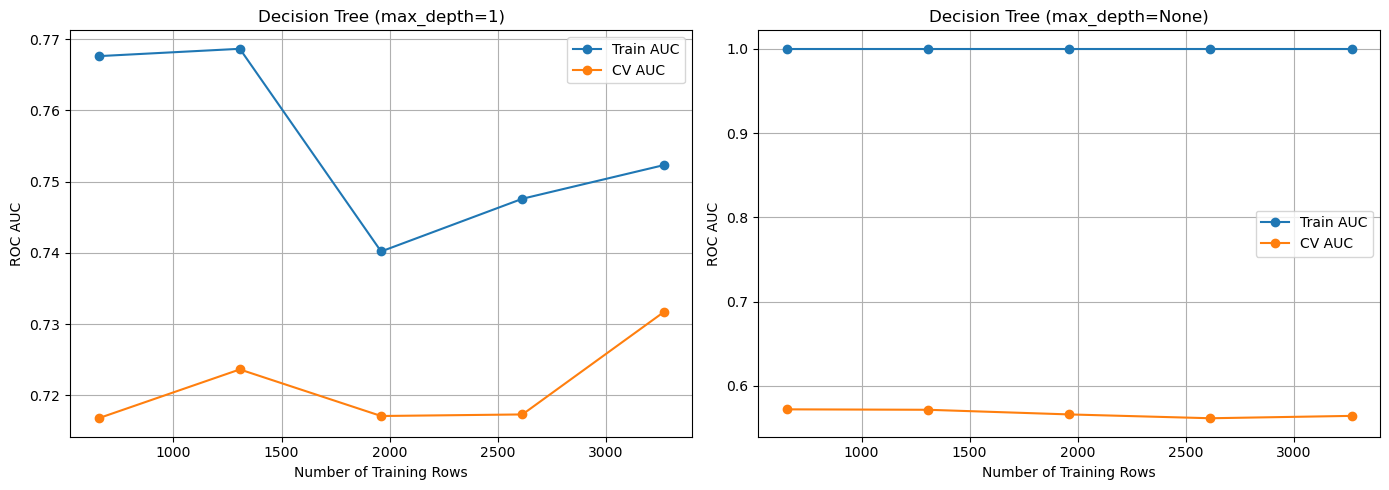

In [9]:
from sklearn.model_selection import learning_curve, StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_sizes = np.linspace(0.2, 1.0, 5)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, depth in zip(axes, [1, None]):
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    sizes, train_scores, cv_scores = learning_curve(model, x_train, y_train, train_sizes=train_sizes, cv=cv, scoring='roc_auc')
    ax.plot(sizes, train_scores.mean(axis=1), marker='o', label='Train AUC')
    ax.plot(sizes, cv_scores.mean(axis=1), marker='o', label='CV AUC')
    ax.set_title(f'Decision Tree (max_depth={depth})')
    ax.set_xlabel('Number of Training Rows')
    ax.set_ylabel('ROC AUC')
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

In [10]:
depths = [1, 3, None]
n_bootstraps = 40
bootstrap_predictions = {}
for depth in depths:
    predictions = []
    for i in range(n_bootstraps):
        sample_idx = np.random.choice(len(x_train), size=len(x_train), replace=True)
        x_boot = x_train.iloc[sample_idx]
        y_boot = y_train.iloc[sample_idx]
        model = DecisionTreeClassifier(max_depth=depth, random_state=42+i)
        model.fit(x_boot, y_boot)
        y_prob = model.predict_proba(x_test)[:, 1]
        predictions.append(y_prob)
    bootstrap_predictions[depth] = np.array(predictions)
for depth in depths:
    print(f"Max Depth: {depth}")
    print("Prediction Shape:", bootstrap_predictions[depth].shape)

Max Depth: 1
Prediction Shape: (40, 1022)
Max Depth: 3
Prediction Shape: (40, 1022)
Max Depth: None
Prediction Shape: (40, 1022)
